# Lab - EDA Univariate Analysis: Diving into Amazon UK Product Insights

**Objective**: Explore the product listing dynamics on Amazon UK to extract actionablebusiness insights (distribution, central tendencies, and relationships of product attributes).

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")
%matplotlib inline

### Load the data

In [2]:
df = pd.read_csv('amz_uk_price_prediction_dataset.csv')
print(df.shape)
df.head()

FileNotFoundError: [Errno 2] No such file or directory: 'amz_uk_price_prediction_dataset.csv'

### A quick but important data-cleaning noteThe dataset uses a `stars` column (not `rating`) for the star rating. Looking at the data,exactly **50.2%** of rows have `stars == 0` **and** `reviews == 0` at the same time -- theseare products that have never been reviewed, not products that genuinely received a 0-starrating. If we leave these in, they would badly distort every rating statistic (mean, skew,etc.), so we treat `stars == 0` as *missing* and exclude those rows from the rating analysisin Part 3. We also rename `stars` to `rating` to match the naming used in this lab.

In [ ]:
df = df.rename(columns={'stars': 'rating'})

# Treat unrated products (rating == 0 and reviews == 0) as missing data for rating purposes
df['rating'] = df['rating'].replace(0, np.nan)

print(f"Products with no rating yet: {df['rating'].isna().sum():,} ({df['rating'].isna().mean():.1%} of all listings)")

Products with no rating yet: 1,225,641 (50.2% of all listings)

## Part 1: Understanding Product Categories**Business Question**: What are the most popular product categories on Amazon UK, and how do they compare in terms of listing frequency?

#### 1. Frequency table for `category`

In [ ]:
category_counts = df['category'].value_counts()
category_counts

category
Sports & Outdoors                         836265
Beauty                                     19312
Handmade Clothing, Shoes & Accessories     19229
Bath & Body                                19092
Birthday Gifts                             18978
                                           ...  
Motorbike Chassis                            107
Alexa Built-In Devices                       107
Plugs                                        107
Smart Home Security & Lighting               104
Smart Speakers                                54
Name: count, Length: 296, dtype: int64

**Top 5 most listed categories:**

In [ ]:
top_5_categories = category_counts.head(5)
top_5_categories

category
Sports & Outdoors                         836265
Beauty                                     19312
Handmade Clothing, Shoes & Accessories     19229
Bath & Body                                19092
Birthday Gifts                             18978
Name: count, dtype: int64

#### 2. Visualizations

First attempt: bar chart of **all** categories (there are 296 of them).

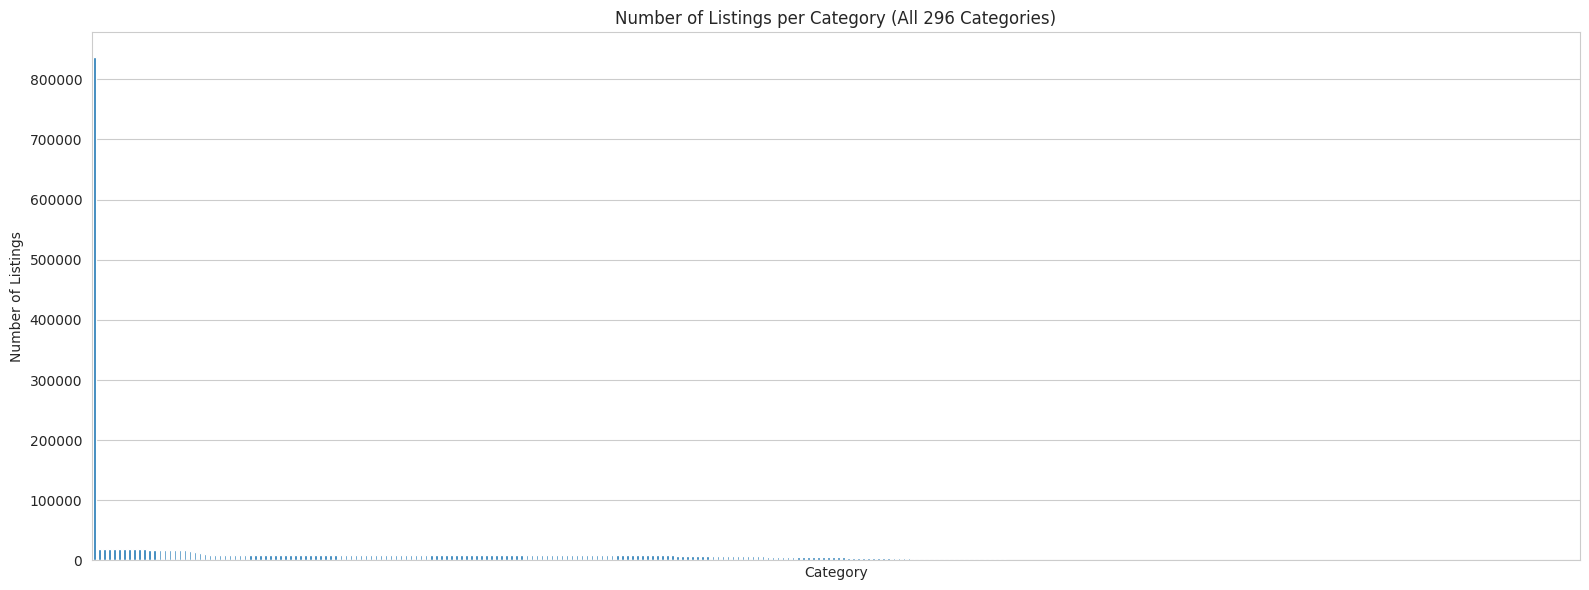

In [ ]:
plt.figure(figsize=(16, 6))
category_counts.plot(kind='bar')
plt.title('Number of Listings per Category (All 296 Categories)')
plt.xlabel('Category')
plt.ylabel('Number of Listings')
plt.xticks([])  # 296 labels are unreadable regardless of rotation
plt.tight_layout()
plt.show()

As expected, with 296 categories the chart above is unreadable -- the x-axis labelsoverlap completely and most bars are too small to compare. Plotting a subset of the topcategories fixes this:

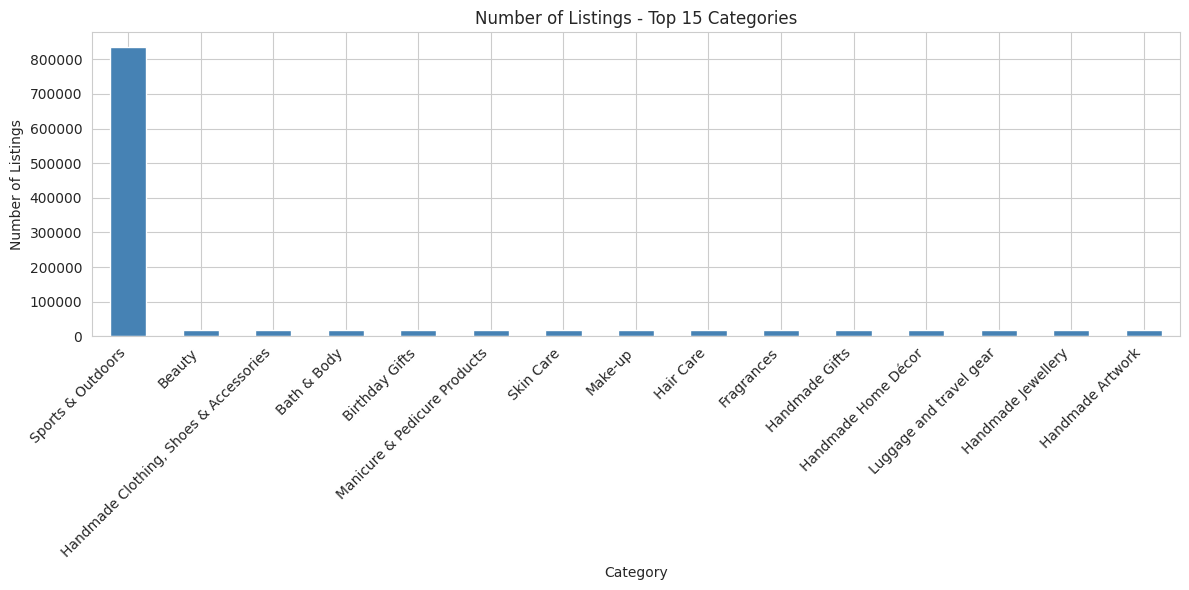

In [ ]:
top_n = category_counts.head(15)

plt.figure(figsize=(12, 6))
top_n.plot(kind='bar', color='steelblue')
plt.title('Number of Listings - Top 15 Categories')
plt.xlabel('Category')
plt.ylabel('Number of Listings')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

Pie chart for the top 5 categories:

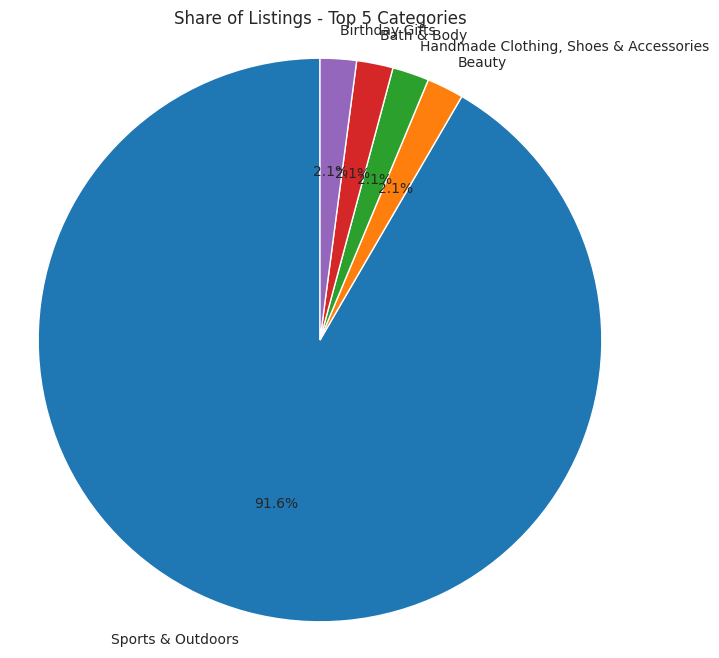

In [ ]:
top_5 = category_counts.head(5)

plt.figure(figsize=(8, 8))
plt.pie(top_5, labels=top_5.index, autopct='%1.1f%%', startangle=90)
plt.title('Share of Listings - Top 5 Categories')
plt.axis('equal')
plt.show()

## Part 2: Delving into Product Pricing**Business Question**: How are products priced on Amazon UK, and are there specific price points or ranges that are more common?

#### 1. Measures of centrality for `price`

In [ ]:
price_mean = df['price'].mean()
price_median = df['price'].median()
price_mode = df['price'].mode()[0]

print(f"Mean price:   £{price_mean:.2f}")
print(f"Median price: £{price_median:.2f}")
print(f"Mode price:   £{price_mode:.2f}")

Mean price:   £89.24
Median price: £19.09
Mode price:   £9.99


#### 2. Measures of dispersion for `price`

In [ ]:
price_var = df['price'].var()
price_std = df['price'].std()
price_range = df['price'].max() - df['price'].min()

Q1_price = df['price'].quantile(0.25)
Q3_price = df['price'].quantile(0.75)
price_iqr = Q3_price - Q1_price

print(f"Variance: {price_var:,.2f}")
print(f"Std dev:  £{price_std:,.2f}")
print(f"Range:    £{price_range:,.2f}")
print(f"IQR:      £{price_iqr:.2f} (Q1=£{Q1_price:.2f}, Q3=£{Q3_price:.2f})")

Variance: 119,445.49
Std dev:  £345.61
Range:    £100,000.00
IQR:      £36.00 (Q1=£9.99, Q3=£45.99)


#### 3. Visualizations

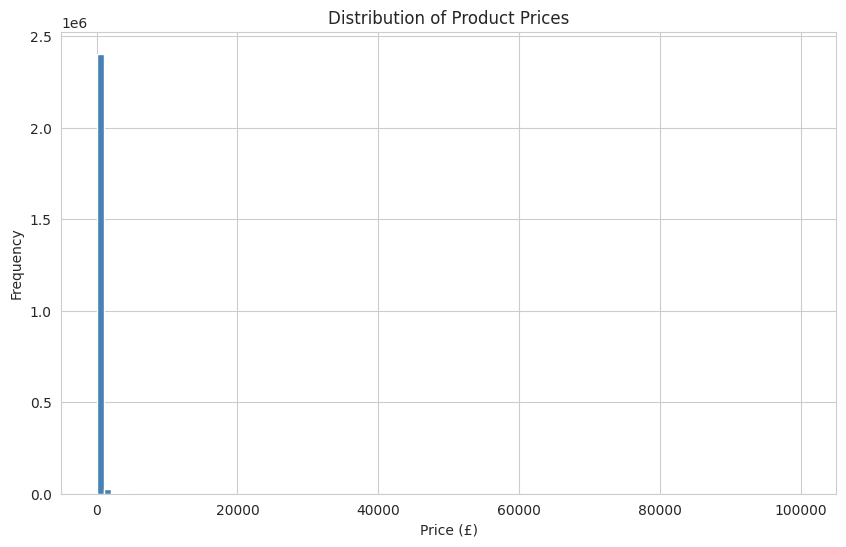

In [ ]:
plt.figure(figsize=(10, 6))
plt.hist(df['price'], bins=100, color='steelblue', edgecolor='white')
plt.title('Distribution of Product Prices')
plt.xlabel('Price (£)')
plt.ylabel('Frequency')
plt.show()

This histogram is hard to read: almost everything is squashed into a single bar near£0, because a handful of products priced in the thousands (max is £100,000) stretch thex-axis so far that the bulk of normally-priced products becomes invisible. A log-scaledy-axis (or restricting to a realistic price range) fixes this:

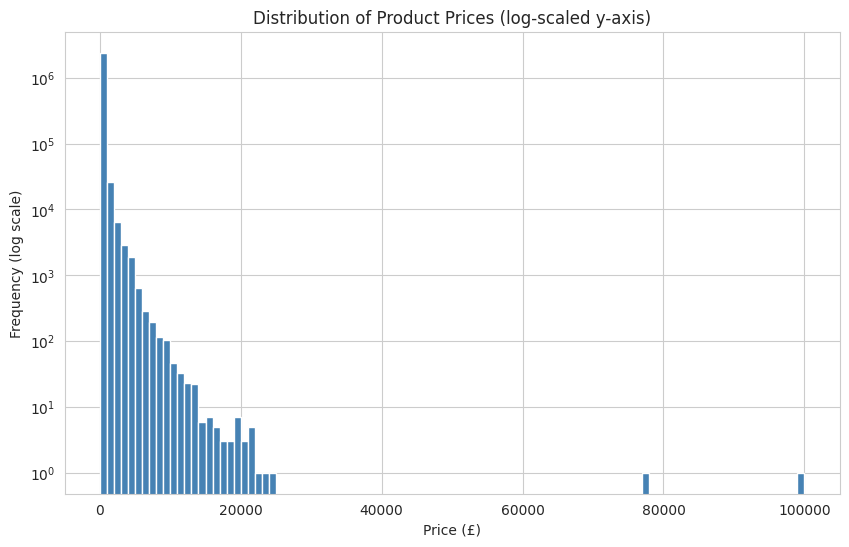

In [ ]:
plt.figure(figsize=(10, 6))
plt.hist(df['price'], bins=100, color='steelblue', edgecolor='white')
plt.yscale('log')
plt.title('Distribution of Product Prices (log-scaled y-axis)')
plt.xlabel('Price (£)')
plt.ylabel('Frequency (log scale)')
plt.show()

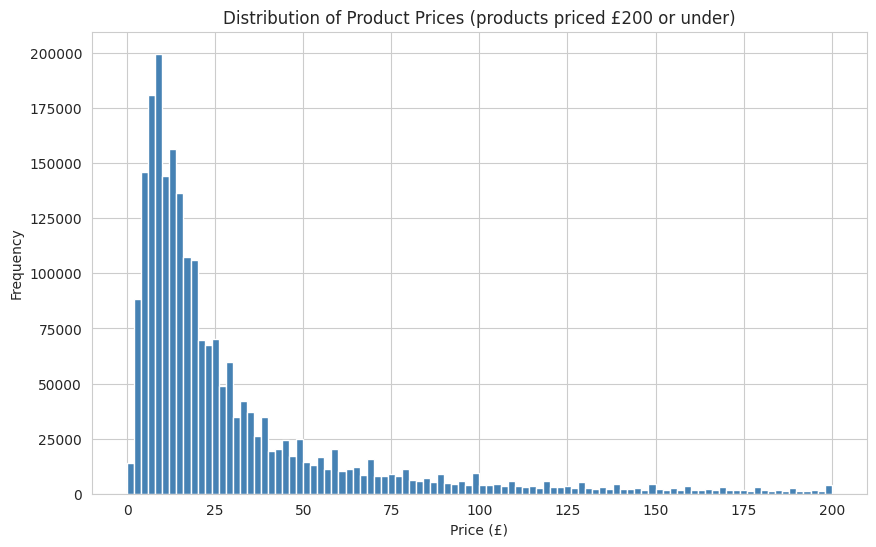

In [ ]:
plt.figure(figsize=(10, 6))
plt.hist(df[df['price'] <= 200]['price'], bins=100, color='steelblue', edgecolor='white')
plt.title('Distribution of Product Prices (products priced £200 or under)')
plt.xlabel('Price (£)')
plt.ylabel('Frequency')
plt.show()

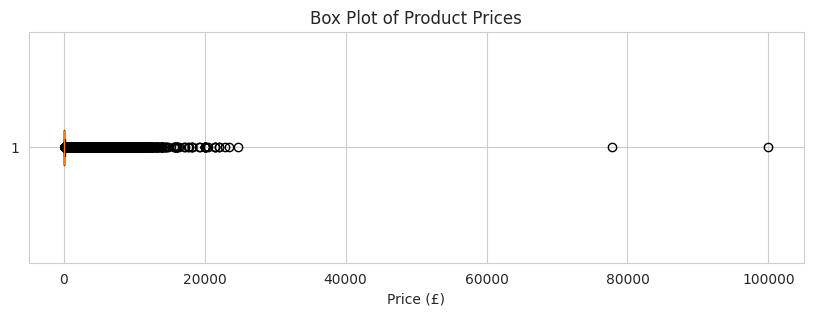

In [ ]:
plt.figure(figsize=(10, 3))
plt.boxplot(df['price'], vert=False)
plt.title('Box Plot of Product Prices')
plt.xlabel('Price (£)')
plt.show()

## Part 3: Unpacking Product Ratings**Business Question**: How do customers rate products on Amazon UK, and are there any patterns or tendencies in the ratings?

_All statistics below use only the products that actually have at least one review (see the data-cleaning note above)._

In [ ]:
rated = df.dropna(subset=['rating'])
print(f"Rated products: {len(rated):,} out of {len(df):,}")

Rated products: 1,218,010 out of 2,443,651


#### 1. Measures of centrality for `rating`

In [ ]:
rating_mean = rated['rating'].mean()
rating_median = rated['rating'].median()
rating_mode = rated['rating'].mode()[0]

print(f"Mean rating:   {rating_mean:.2f}")
print(f"Median rating: {rating_median:.2f}")
print(f"Mode rating:   {rating_mode:.2f}")

Mean rating:   4.32
Median rating: 4.40
Mode rating:   4.50


#### 2. Measures of dispersion for `rating`

In [ ]:
rating_var = rated['rating'].var()
rating_std = rated['rating'].std()

Q1_rating = rated['rating'].quantile(0.25)
Q3_rating = rated['rating'].quantile(0.75)
rating_iqr = Q3_rating - Q1_rating

print(f"Variance: {rating_var:.3f}")
print(f"Std dev:  {rating_std:.3f}")
print(f"IQR:      {rating_iqr:.3f} (Q1={Q1_rating:.2f}, Q3={Q3_rating:.2f})")

Variance: 0.308
Std dev:  0.555
IQR:      0.500 (Q1=4.10, Q3=4.60)


#### 3. Shape of the distribution

In [ ]:
rating_skew = rated['rating'].skew()
rating_kurtosis = rated['rating'].kurt()  # excess kurtosis (0 = normal)

print(f"Skewness: {rating_skew:.3f}")
print(f"Kurtosis: {rating_kurtosis:.3f}")

Skewness: -2.380
Kurtosis: 9.782


#### 4. Visualization

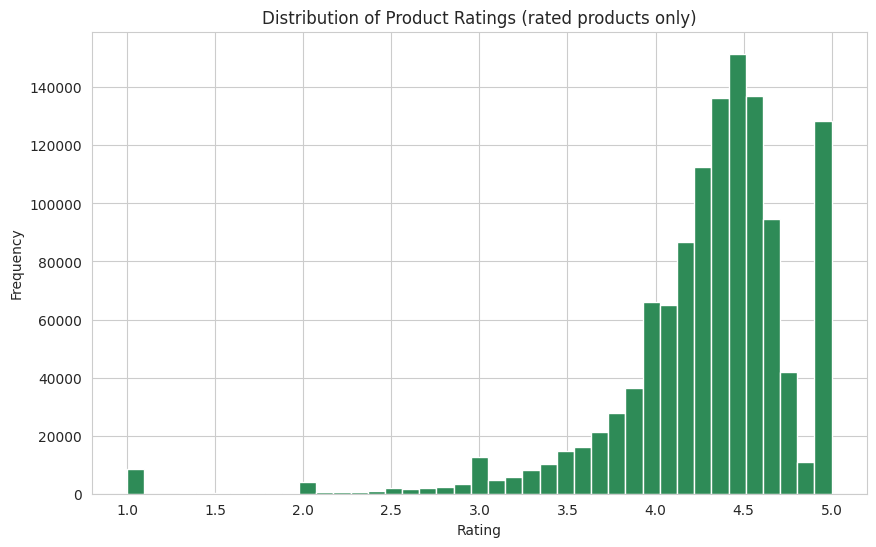

In [ ]:
plt.figure(figsize=(10, 6))
plt.hist(rated['rating'], bins=41, color='seagreen', edgecolor='white')
plt.title('Distribution of Product Ratings (rated products only)')
plt.xlabel('Rating')
plt.ylabel('Frequency')
plt.show()

---
## Business-Centric Summary

- **Categories**: There are 296 categories, but the distribution is extremely lopsided.
  "Sports & Outdoors" alone accounts for **34.2%** of all 2.44M listings (836,265 products) --
  more than 40x the next-largest category (Beauty, at 0.8%). This gap is so extreme it is
  worth double-checking the category taxonomy (it may be acting as a broad catch-all bucket
  rather than a genuinely dominant market segment) before using it to drive inventory decisions.
- **Pricing**: mean price (£89.24) is more than 4x the median (£19.09) and roughly 9x the mode
  (£9.99), confirming a strong right skew. The standard deviation (£345.61) dwarfs the IQR
  (£36.00), meaning a relatively small number of very expensive products (prices go up to
  £100,000) are inflating the spread. For most business purposes (e.g. "typical" pricing
  strategy), the median/mode are far more representative than the mean.
- **Ratings**: 50.2% of all listings (1,225,641 products) have never been reviewed and were
  excluded from the rating analysis. Among the ~1.22M rated products, ratings are tightly
  clustered between 4.1 and 4.6 stars (mean 4.32, median 4.40, mode 4.50, IQR only 0.50), and
  the distribution is strongly negatively skewed (-2.38) and sharply peaked (kurtosis 9.78) --
  i.e. the vast majority of rated products are well-liked, with a comparatively small tail of
  poorly-rated products pulling the distribution's tail toward low values. This suggests that
  a low-rated product on this platform is very much the exception rather than the norm, which
  is useful context when triaging customer complaints or quality issues.
